# Quote risk and revaluation for a mixed portfolio

A pay-fixed swap can offset some of a bond's interest-rate exposure. To
examine that offset, we combine a USD 1 million pay-fixed swap, a USD 500,000
fixed-rate bond at zero Z-spread and a USD 2 million caplet. The market is the
illustrative SOFR curve and Black surface dated 24 February 2026.

We value the trades, aggregate sensitivities by input quote and compare their
linear P&L estimate with full scenario revaluation:

$$\Delta V\approx\sum_j\frac{\partial V}{\partial q_j}\Delta q_j.$$

All position values are in USD. Rate, volatility and bond-spread inputs use
their own quotation units. The calculation measures today's portfolio risk;
legal netting and future credit exposure are developed in the
[XVA study](../cva/xva.ipynb). [Setup](../README.md).


In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import quantsupport as qs
from market_data import load_market

market = load_market()
ref = market.quotes.reference_date
swap = qs.Swap(
    identifier="BOOK-SWAP",
    start_date=ref,
    maturity_date=ref + "5Y",
    notional=1_000_000,
    fixed_rate=0.04,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
)
bond = qs.FixedRateBond(
    identifier="BOOK-BOND",
    start_date=ref,
    maturity_date=ref + "5Y",
    notional=500_000,
    rate=0.045,
    currency=qs.Currency.USD,
    payment_frequency=qs.Frequency.Semiannual,
)
caplet = qs.CapletFloorlet(
    identifier="BOOK-CAPLET",
    fixing_date=ref + "2Y",
    start_accrual_date=ref + "2Y",
    end_accrual_date=ref + "2Y3M",
    payment_date=ref + "2Y3M",
    strike=0.045,
    currency=qs.Currency.USD,
    market_index=qs.MarketIndex.SOFR,
    payoff_type=qs.CapletFloorletType.Caplet,
)
portfolio = [
    qs.Trade(swap, ref, qs.Side.PayShort),
    qs.Trade(bond, ref, pricing_anchor=qs.BondPricingAnchor.z_spread(0.0)),
    qs.Trade(caplet, ref, notional=2_000_000),
]


## Valuing the positions

Each trade receives requests supported by its pricer. The swap supplies its
par coupon and cashflows, the bond adds yield and duration analytics, and the
caplet supplies value and sensitivities. The bond's zero Z-spread is an
explicit trade anchor.

We retain trade identifiers when collecting the results. Grouping risk by
`pillar` then adds signed exposure to the same market input across positions,
so hedging offsets remain visible. Unavailable analytics stay unpopulated.


In [2]:
extra_requests = {
    swap.identifier: [qs.Request.FairRate(0), qs.Request.Cashflows],
    bond.identifier: [
        qs.Request.YieldToMaturity,
        qs.Request.ModifiedDuration,
        qs.Request.ZSpread,
        qs.Request.Cashflows,
    ],
    caplet.identifier: [],
}
results = []
risk_tables = []
cashflow_tables = []
context = qs.PricingContext(
    quotes=market.quotes,
    curves=market.curves,
    csa_policy=market.csa_policy,
    volatility_surfaces=market.volatility_surfaces,
)

with context:
    for trade in portfolio:
        result = context.evaluate(
            trade,
            [
                qs.Request.Value,
                qs.Request.Sensitivities,
                *extra_requests[trade.instrument.identifier],
            ],
        )
        results.append(
            {
                "trade": result.identifier,
                "pv_usd": result.price,
                "fair_rate": result.fair_rate,
                "ytm": result.yield_to_maturity,
                "modified_duration": result.modified_duration,
            }
        )
        risk_tables.append(result.sensitivities.assign(trade=result.identifier))
        if result.cashflows is not None:
            payments = result.cashflows.loc[
                result.cashflows["payment_date"] > str(ref)
            ].copy()
            payments["fixing"] = payments["fixing"].astype(float)
            payments["signed_amount_usd"] = payments["amount"]
            cashflow_tables.append(payments.assign(trade=result.identifier))

valuation = pd.DataFrame(results).set_index("trade")
trade_risk = pd.concat(risk_tables, ignore_index=True)
portfolio_risk = trade_risk.groupby("pillar")["value"].sum()
portfolio_pv = valuation["pv_usd"].sum()
print(f"Portfolio PV: USD {portfolio_pv:,.2f}")
valuation


Portfolio PV: USD 513,286.73


,pv_usd,fair_rate,ytm,modified_duration
trade,,,,
BOOK-SWAP,1664.892276,0.040368,NaN,NaN
BOOK-BOND,510478.041062,NaN,0.044142,3.786059
BOOK-CAPLET,1143.799136,NaN,NaN,NaN


## Scaling the risk report

A sensitivity is the PV derivative per unit change in its named input.
Multiply rate and Z-spread derivatives by `1e-4` for a one-basis-point move,
and Black-volatility derivatives by `0.01` for one volatility point.

The construction specifications identify each quote family. The matrix below
preserves individual trade contributions before adding their signed total,
allowing us to inspect where the swap offsets the bond.


In [3]:
rate_labels = market.curves[0].to_dict()["quotes"]
vol_labels = market.volatility_surfaces[0].to_dict()["quotes"]
known_risk_labels = set(rate_labels) | set(vol_labels) | {bond.identifier + ".ZSpread"}
assert set(portfolio_risk.index) <= known_risk_labels

rate_derivatives = portfolio_risk.reindex(rate_labels, fill_value=0)
rate_risk = pd.DataFrame({"dPV_dQuote": rate_derivatives})
rate_risk["pnl_plus_1bp_usd"] = rate_derivatives * 1e-4
vol_derivatives = portfolio_risk.reindex(vol_labels, fill_value=0)
vol_risk = pd.DataFrame({"dPV_dQuote": vol_derivatives})
vol_risk["pnl_plus_1vol_point_usd"] = vol_derivatives * 0.01
spread_risk = portfolio_risk[portfolio_risk.index.str.endswith(".ZSpread")] * 1e-4

contributions = trade_risk.pivot_table(
    index="pillar", columns="trade", values="value", aggfunc="sum", fill_value=0
)
rate_contributions = contributions.reindex(rate_labels, fill_value=0) * 1e-4
rate_contributions["portfolio"] = rate_contributions.sum(axis=1)
rate_contributions


trade,BOOK-BOND,BOOK-CAPLET,BOOK-SWAP,portfolio
pillar,,,,
FixedRateDeposit_USD_SOFR_1D,-0.141782,-0.000318,0.277281,0.135181
OIS_USD_SOFR_1Y,-0.357122,-0.938500,0.304983,-0.990638
OIS_USD_SOFR_2Y,-0.351285,-28.670557,-0.112762,-29.134605
OIS_USD_SOFR_3Y,-1.273675,44.490311,0.631545,43.848182
OIS_USD_SOFR_5Y,-222.268675,0.000000,441.832926,219.564251
OIS_USD_SOFR_7Y,0.000000,0.000000,0.000000,0.000000
OIS_USD_SOFR_10Y,0.000000,0.000000,0.000000,0.000000
OIS_USD_SOFR_30Y,0.000000,0.000000,0.000000,0.000000


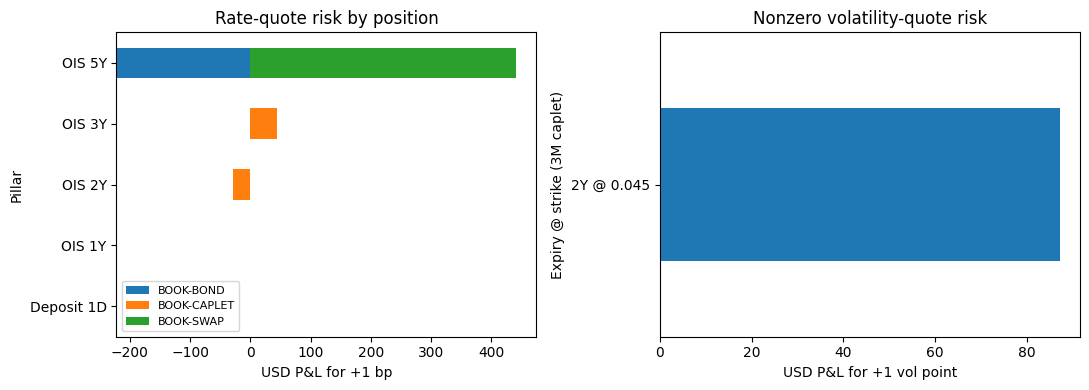

In [4]:
rate_plot = rate_contributions.drop(columns="portfolio")
rate_plot = rate_plot.loc[rate_plot.abs().max(axis=1) > 1e-8].copy()
rate_plot.index = rate_plot.index.str.replace(
    "FixedRateDeposit_USD_SOFR_", "Deposit ", regex=False
).str.replace("OIS_USD_SOFR_", "OIS ", regex=False)
vol_plot = vol_risk.loc[
    vol_risk["pnl_plus_1vol_point_usd"].abs() > 1e-8, "pnl_plus_1vol_point_usd"
]
vol_plot = vol_plot.nlargest(6).copy()
vol_plot.index = (
    vol_plot.index.str.replace("CapletFloorlet_USD_SOFR_3M_", "", regex=False)
    .str.replace("_Absolute_", " @ ", regex=False)
    .str.replace("_Straddle_Black", "", regex=False)
)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
rate_plot.plot.barh(stacked=True, ax=axes[0])
axes[0].set(
    title="Rate-quote risk by position", xlabel="USD P&L for +1 bp", ylabel="Pillar"
)
axes[0].legend(loc="lower left", fontsize=8)
vol_plot.plot.barh(ax=axes[1])
axes[1].set(
    title="Nonzero volatility-quote risk",
    xlabel="USD P&L for +1 vol point",
    ylabel="Expiry @ strike (3M caplet)",
)
plt.tight_layout()
plt.show()


## Comparing derivatives with full revaluation

A small central bump checks the aggregate local derivative. We shift deposit
and OIS rate quotes together, rebuild the market and reprice the portfolio,
while retaining volatility quotes and the bond's zero spread.

A central difference using ±1 bp should closely match the summed rate-quote
derivatives. We also apply a +100 bp stress to examine the effect of curvature
and recalibration on the linear prediction.


In [5]:
def portfolio_under_quote_shift(bump, labels=rate_labels):
    shocks = [
        qs.Shock(target=label, value=bump, shock_type=qs.ScenarioType.Absolute)
        for label in labels
    ]
    context = qs.PricingContext(
        quotes=market.quotes,
        curves=market.curves,
        csa_policy=market.csa_policy,
        volatility_surfaces=market.volatility_surfaces,
    )

    with context, qs.Scenario(shocks=shocks):
        values = []
        for trade in portfolio:
            value = context.evaluate(trade, [qs.Request.Value]).price
            values.append(value)
        return sum(values)


plus = portfolio_under_quote_shift(1e-4)
minus = portfolio_under_quote_shift(-1e-4)
central_derivative = (plus - minus) / (2e-4)
aad_derivative = rate_risk["dPV_dQuote"].sum()
print("AAD derivative:", aad_derivative)
print("Central-difference derivative:", central_derivative)

stress_pv = portfolio_under_quote_shift(0.01)
pd.DataFrame(
    [
        {
            "shock": "+1 bp",
            "full_pnl_usd": plus - portfolio_pv,
            "linear_pnl_usd": aad_derivative * 1e-4,
        },
        {
            "shock": "+100 bp",
            "full_pnl_usd": stress_pv - portfolio_pv,
            "linear_pnl_usd": aad_derivative * 0.01,
        },
    ]
).assign(
    nonlinear_residual_usd=lambda frame: frame["full_pnl_usd"] - frame["linear_pnl_usd"]
)


AAD derivative: 2334223.707692427
Central-difference derivative: 2334223.7382306485


,shock,full_pnl_usd,linear_pnl_usd,nonlinear_residual_usd
0,+1 bp,233.416053,233.422371,-0.006317
1,+100 bp,23259.688553,23342.237077,-82.548524


## Aggregating signed payments

The swap and bond reports already contain signed amounts: receipts are positive
and payments are negative. Grouping the reported amounts by date and currency
gives the portfolio's projected payment schedule.

We retain payments strictly after valuation, excluding initial advances.
The table covers the swap and bond; the caplet's future exercise payment
requires an option calculation. Discounting the included receipts provides
a separate reconciliation to their position values.


In [6]:
cashflows = pd.concat(cashflow_tables, ignore_index=True)
payment_report = (
    cashflows.groupby(["payment_date", "currency"])["signed_amount_usd"]
    .sum()
    .to_frame()
)
payment_report.head(12)


,,signed_amount_usd
payment_date,currency,
2026-08-24,USD,15220.978571
2027-02-24,USD,15484.516666
2027-08-24,USD,12200.675779
2028-02-24,USD,12301.221730
2028-08-24,USD,9702.338357
2029-02-24,USD,9726.065575
2029-08-24,USD,9992.471336
2030-02-24,USD,10170.881318
2030-08-24,USD,10002.140323


## Checking risk and cashflow values

Central differences use $[V(q+h)-V(q-h)]/(2h)$. We test rate and volatility
inputs separately while holding the bond spread fixed.

Scenario matching uses sets of underscore-separated identifier segments.
A single `CapletFloorlet_USD_SOFR` selector moves the volatility family once;
enumerating every full caplet identifier can produce overlapping matches.
The volatility-market study checks the selected inputs directly.

Finally, we discount the signed swap and bond payments and compare their
sums with the reported values.


In [7]:
import math

assert math.isclose(central_derivative, aad_derivative, rel_tol=2e-4, abs_tol=0.1)
vol_bump = 1e-4
vol_plus = portfolio_under_quote_shift(vol_bump, ["CapletFloorlet_USD_SOFR"])
vol_minus = portfolio_under_quote_shift(-vol_bump, ["CapletFloorlet_USD_SOFR"])
vol_central = (vol_plus - vol_minus) / (2 * vol_bump)
vol_aad = vol_risk["dPV_dQuote"].sum()
assert math.isclose(vol_central, vol_aad, rel_tol=2e-4, abs_tol=0.1)
assert math.isclose(
    portfolio_risk.sum(), trade_risk.groupby("trade")["value"].sum().sum(), abs_tol=1e-8
)
with context:
    curve = context.curve(qs.MarketIndex.SOFR)
    signed_payments = cashflows.copy()
    signed_payments["discount_factor"] = signed_payments["payment_date"].map(
        curve.discount_factor
    )
signed_payments["pv_usd"] = (
    signed_payments["signed_amount_usd"] * signed_payments["discount_factor"]
)
reconstructed = signed_payments.groupby("trade")["pv_usd"].sum()
for identifier, value in reconstructed.items():
    assert math.isclose(value, valuation.loc[identifier, "pv_usd"], abs_tol=1e-6)
print(
    f"Parallel rate AAD/finite difference: {aad_derivative:,.4f} / {central_derivative:,.4f} USD per unit."
)
print(
    f"Parallel vol AAD/finite difference: {vol_aad:,.4f} / {vol_central:,.4f} USD per unit."
)
print("Signed cashflow PVs reconcile for both the swap and bond.")
pd.DataFrame(
    {
        "native_pv_usd": valuation.loc[reconstructed.index, "pv_usd"],
        "cashflow_pv_usd": reconstructed,
    }
)


Parallel rate AAD/finite difference: 2,334,223.7077 / 2,334,223.7382 USD per unit.
Parallel vol AAD/finite difference: 8,730.5024 / 8,730.5022 USD per unit.
Signed cashflow PVs reconcile for both the swap and bond.


,native_pv_usd,cashflow_pv_usd
trade,,
BOOK-BOND,510478.041062,510478.041062
BOOK-SWAP,1664.892276,1664.892276


The trade-level matrix shows how the pay-fixed swap offsets the bond's rate
risk while leaving the caplet's volatility exposure and the bond's independent
spread exposure. The stress residual measures how that local hedge changes
under a larger move. Retain the input labels and scaling conventions when
exporting these reports.


Export the tables with `valuation.to_csv(...)`, `trade_risk.to_csv(...)` or
`rate_risk.to_csv(...)`. For future exposure under client agreements, continue
with [netting and XVA](../cva/xva.ipynb).
